## GAN - Aula Prática

## Configurações

Importando módulos necessários e baixando os datasets.

In [56]:
import glob
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as colors

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision.datasets import ImageFolder
import torchvision.transforms.v2 as transforms
import torchvision.transforms.v2.functional as K
from torchvision.utils import make_grid

from tqdm.notebook import tqdm
from sklearn.model_selection import train_test_split
from skimage import io
from torchinfo import summary

In [7]:
!wget -O ./data/cebradata.zip -nc https://www.kaggle.com/api/v1/datasets/download/alsaniipe/cebradata
!wget -O ./data/anime-faces.zip -nc https://www.kaggle.com/api/v1/datasets/download/soumikrakshit/anime-faces
!unzip -q -n data/cebradata.zip -d ./data/cebradata
!unzip -q -n data/anime-faces.zip -d ./data/anime-faces

File './data/cebradata.zip' already there; not retrieving.


File './data/art-portraits.zip' already there; not retrieving.
File './data/anime-faces.zip' already there; not retrieving.


# Introdução

GANs (Generative Adversarial Networks) são uma arquitetura de rede neural que tem como objetivo gerar novos dados a partir de um conjunto de dados de treinamento. A ideia é que a rede neural seja capaz de aprender a distribuição dos dados de treinamento e, a partir disso, gerar novos dados que sejam semelhantes aos dados de treinamento. Neste notebook, vamos implementar uma GAN para gerar imagens de personagens de anime.

## Dataset

O dataset que vamos utilizar é o [Anime Faces](https://www.kaggle.com/splcher/animefacedataset), que contém imagens de personagens de anime. O dataset contém 63.000 imagens de personagens de anime, com dimensões 64x64 pixels.

Escolhemos este dataset por ser relativamente pequeno e por conter imagens de personagens de anime, que são mais simples e possuem menos variações do que imagens de pessoas reais. Isso facilita o treinamento da GAN.

In [165]:
anime_faces_path = './data/anime-faces'

In [57]:
# function to plot samples and metadata of a dataset
def plot_dataset(dataset, n_rows=4, n_cols=4, figsize=(6, 6), denormalize=False):
    print(f'Number of samples: {len(dataset)}')
    print(f'Sample shape: {dataset[0][0].shape}')

    samples = np.random.randint(0, len(dataset), size=(n_rows, n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize)

    for i in range(n_rows):
        for j in range(n_cols):
            image, _ = dataset[samples[i, j]]
            if denormalize:
                image = K.normalize(image, -1, 2)
                image = image.clamp(0, 1)
            image = image.permute(1,2,0)
            axes[i, j].imshow(image)
            axes[i, j].axis('off')
    
    plt.show()

In [58]:
anime_faces = ImageFolder(
    anime_faces_path,
    transform=transforms.Compose(
        [
            transforms.ToImage(),
            transforms.ToDtype(torch.float32, scale=True),
            transforms.Resize((64, 64)),
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
        ]
    ),
)

Number of samples: 43102
Sample shape: torch.Size([3, 64, 64])


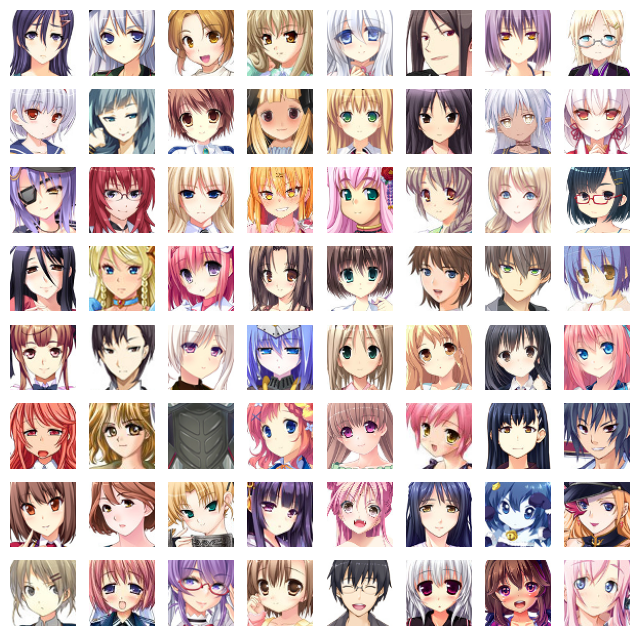

In [59]:
plot_dataset(anime_faces, n_cols=8, n_rows=8, denormalize=True, figsize=(8, 8))

## Modelo

A GAN é composta por duas redes neurais: o gerador e o discriminador. O gerador é responsável por gerar novas imagens, enquanto o discriminador é responsável por distinguir entre imagens reais e imagens geradas. O treinamento da GAN é feito de forma adversarial: o gerador tenta gerar imagens que enganem o discriminador, enquanto o discriminador tenta distinguir entre imagens reais e imagens geradas.

A imagem abaixo ilustra a ideia por trás da arquitetura de uma GAN:

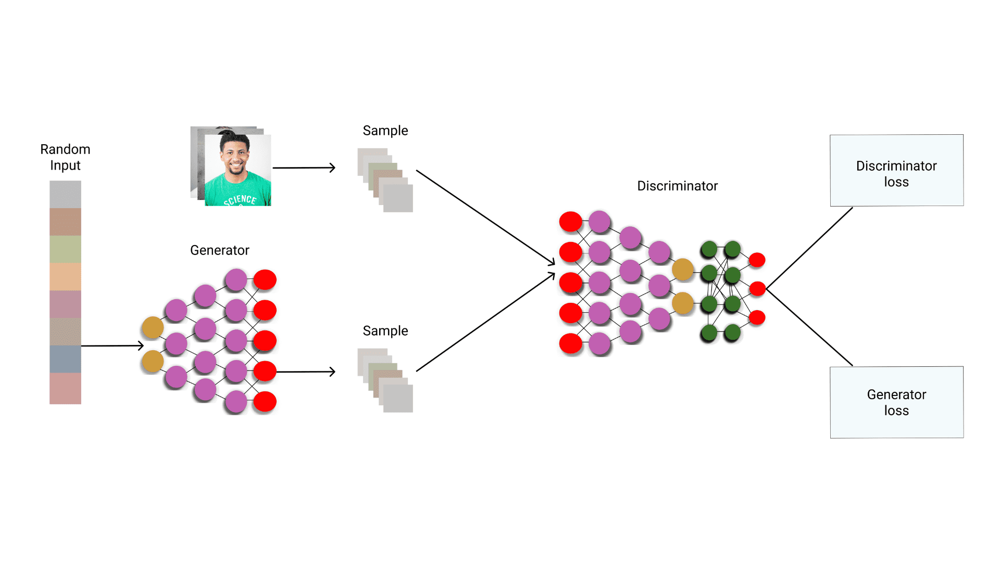

### Gerador

O gerador é uma rede neural que recebe um vetor de valores aleatórios como entrada (a semente da geração) e gera uma imagem como saída. A ideia é que o gerador aprenda a mapear vetores de números aleatórios para imagens que sejam semelhantes às imagens de treinamento. O gerador é treinado para enganar o discriminador, ou seja, para gerar imagens que o discriminador classifica como reais.

In [60]:
def plot_generated_images(generator, num_images=64, latent_dim=128, figsize=(6, 6), device='cpu', denormalize=False):
    # generator.eval()
    with torch.no_grad():
        noise = torch.randn(num_images, latent_dim, 1, 1).to(device)
        generated_images = generator(noise).cpu()

    generated_images = generated_images.permute(0, 2, 3, 1)
    if denormalize:
        generated_images = K.normalize(generated_images, -1, 2)  # Normalize to (0, 1)
    
    n_rows = int(math.sqrt(num_images))
    n_cols = int(math.sqrt(num_images))
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize)
    for i in range(n_rows):
        for j in range(n_cols):
            axes[i, j].imshow(generated_images[i * n_cols + j])
            axes[i, j].axis('off')
    
    plt.show()

In [61]:
class Generator(nn.Module):
    def __init__(self, latent_size=128, output_dim=3):
        super(Generator, self).__init__()

        # latent_size is the size of the input noise vector
        self.latent_size = latent_size
        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_size, 512, kernel_size=4, stride=1, bias=False),  # (512, 4, 4)
            nn.BatchNorm2d(512),
            nn.GELU(),
            nn.ConvTranspose2d(512, 256, kernel_size=4, stride=2, padding=1, bias=False),  # (256, 8, 8)
            nn.BatchNorm2d(256),
            nn.GELU(),
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1, bias=False),  # (128, 16, 16)
            nn.BatchNorm2d(128),
            nn.GELU(),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1, bias=False),  # (64, 32, 32)
            nn.BatchNorm2d(64),
            nn.GELU(),
            nn.ConvTranspose2d(64, output_dim, kernel_size=4, stride=2, padding=1, bias=False),  # (output_dim, 64, 64)
            nn.Tanh()
        )
    
    def forward(self, x=None, batch_size=1):
        if x is None:
            device = next(self.parameters()).device
            x = torch.randn(batch_size, self.latent_size, 1, 1, device=device)
        
        return self.net(x)

In [62]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
generator = Generator(output_dim=3)
generator.to(device)
summary(generator, (256, 128, 1, 1))

Layer (type:depth-idx)                   Output Shape              Param #
Generator                                [256, 3, 64, 64]          --
├─Sequential: 1-1                        [256, 3, 64, 64]          --
│    └─ConvTranspose2d: 2-1              [256, 512, 4, 4]          1,048,576
│    └─BatchNorm2d: 2-2                  [256, 512, 4, 4]          1,024
│    └─GELU: 2-3                         [256, 512, 4, 4]          --
│    └─ConvTranspose2d: 2-4              [256, 256, 8, 8]          2,097,152
│    └─BatchNorm2d: 2-5                  [256, 256, 8, 8]          512
│    └─GELU: 2-6                         [256, 256, 8, 8]          --
│    └─ConvTranspose2d: 2-7              [256, 128, 16, 16]        524,288
│    └─BatchNorm2d: 2-8                  [256, 128, 16, 16]        256
│    └─GELU: 2-9                         [256, 128, 16, 16]        --
│    └─ConvTranspose2d: 2-10             [256, 64, 32, 32]         131,072
│    └─BatchNorm2d: 2-11                 [256, 64, 32, 3

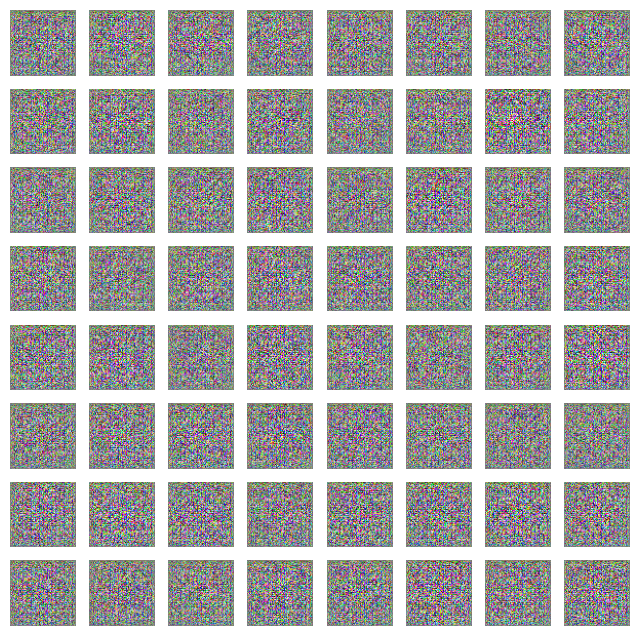

In [63]:
plot_generated_images(generator, device=device, num_images=64, denormalize=True, figsize=(8, 8))

### Discriminador

O discriminador é uma rede neural que recebe uma imagem como entrada e classifica se a imagem é real (vinda do conjunto de treinamento) ou falsa (gerada). O discriminador é treinado para distinguir entre imagens reais e falsas.

In [64]:
class Discrimiminator(nn.Module):
    def __init__(self, in_channels=3):
        super(Discrimiminator, self).__init__()

        self.net = nn.Sequential(
            nn.Conv2d(in_channels, 64, kernel_size=4, stride=2, padding=1, bias=False), # (64, 32, 32)
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),  # (128, 16, 16)
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),
            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1, bias=False),  # (256, 8, 8)
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2),
            nn.Conv2d(256, 512, kernel_size=4, stride=2, padding=1, bias=False),  # (512, 4, 4)
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2),
            nn.Conv2d(512, 1, kernel_size=4, bias=False),  # (1, 1, 1)
            nn.Flatten(),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x)

In [65]:
discriminator = Discrimiminator()
discriminator.to(device)
summary(discriminator, (128, 3, 64, 64))

Layer (type:depth-idx)                   Output Shape              Param #
Discrimiminator                          [128, 1]                  --
├─Sequential: 1-1                        [128, 1]                  --
│    └─Conv2d: 2-1                       [128, 64, 32, 32]         3,072
│    └─BatchNorm2d: 2-2                  [128, 64, 32, 32]         128
│    └─LeakyReLU: 2-3                    [128, 64, 32, 32]         --
│    └─Conv2d: 2-4                       [128, 128, 16, 16]        131,072
│    └─BatchNorm2d: 2-5                  [128, 128, 16, 16]        256
│    └─LeakyReLU: 2-6                    [128, 128, 16, 16]        --
│    └─Conv2d: 2-7                       [128, 256, 8, 8]          524,288
│    └─BatchNorm2d: 2-8                  [128, 256, 8, 8]          512
│    └─LeakyReLU: 2-9                    [128, 256, 8, 8]          --
│    └─Conv2d: 2-10                      [128, 512, 4, 4]          2,097,152
│    └─BatchNorm2d: 2-11                 [128, 512, 4, 4]     

## Treinando o modelo

Vamos treinar o modelo para reconstruir imagens do dataset. O modelo será treinado por 32 épocas, com batch size 128 e otimizador Adam.

In [162]:
def train(
    generator,
    discriminator,
    train_loader,
    val_loader,
    g_optimizer,
    d_optimizer,
    criterion,
    device,
    epochs=24,
    plot_frequency=None,
):
    generator.to(device)
    discriminator.to(device)

    g_losses_train = []
    d_losses_train = []
    d_accuracies_train = []
    real_scores_train = []
    fake_scores_train = []

    if val_loader is not None:
        g_losses_val = []
        d_losses_val = []
        d_accuracies_val = []
        real_scores_val = []
        fake_scores_val = []

    for epoch in range(epochs):
        generator.train()
        discriminator.train()

        g_loss_train = 0.0
        d_loss_train = 0.0
        d_batch_accuracy = 0.0
        real_score = 0.0
        fake_score = 0.0

        for i, (images, _) in (
            pbar := tqdm(enumerate(train_loader), total=len(train_loader), unit='batch')
        ):
            real_images = images.to(device, non_blocking=True)
            batch_size = real_images.size(0)


            # Train discriminator
            d_optimizer.zero_grad()

            real_outputs = discriminator(real_images)
            real_labels = torch.ones_like(real_outputs, device=device)
            real_loss = criterion(real_outputs, real_labels)

            noise = torch.randn(batch_size, generator.latent_size, 1, 1, device=device)
            fake_images = generator(noise)
            fake_outputs = discriminator(fake_images.detach())
            fake_labels = torch.zeros_like(fake_outputs, device=device)
            fake_loss = criterion(fake_outputs, fake_labels)

            batch_accuracy = (torch.mean(real_outputs >= 0.5, dtype=torch.float32) + torch.mean(fake_outputs < 0.5, dtype=torch.float32)) / 2
            d_batch_accuracy += batch_accuracy.item()

            d_loss = real_loss + fake_loss
            d_loss_train += d_loss.item()
            real_score += real_outputs.mean().item()
            fake_score += fake_outputs.mean().item()
            
            d_loss.backward()
            d_optimizer.step()

            # Train generator
            g_optimizer.zero_grad()

            noise = torch.randn(batch_size, generator.latent_size, 1, 1, device=device)
            fake_images = generator(noise)
            fake_outputs = discriminator(fake_images)
            
            g_loss = criterion(fake_outputs, real_labels)
            g_loss_train += g_loss.item()

            g_loss.backward()
            g_optimizer.step()

            pbar.set_description(
                f'Epoch {epoch+1}/{epochs} G_Loss: {g_loss_train/((i+1)):.4f} D_Loss: {d_loss_train/(i+1):.4f}'
            )

        g_loss_train /= (len(train_loader))
        d_loss_train /= len(train_loader)
        d_accuracy_train = d_batch_accuracy / (len(train_loader))
        real_score /= len(train_loader)
        fake_score /= len(train_loader)

        g_losses_train.append(g_loss_train)
        d_losses_train.append(d_loss_train)
        d_accuracies_train.append(d_accuracy_train)
        real_scores_train.append(real_score)
        fake_scores_train.append(fake_score)

        if val_loader is not None:
            with torch.no_grad():
                generator.eval()
                discriminator.eval()

                g_loss_val = 0.0
                d_loss_val = 0.0
                d_batch_accuracy = 0.0
                real_score = 0.0
                fake_score = 0.0

                for images, _ in val_loader:
                    real_images = images.to(device, non_blocking=True)
                    batch_size = real_images.size(0)


                    # Evaluate discriminator

                    real_outputs = discriminator(real_images)
                    real_labels = torch.ones_like(real_outputs, device=device)
                    real_loss = criterion(real_outputs, real_labels)

                    # Generate fake images
                    noise = torch.randn(batch_size, generator.latent_size, 1, 1, device=device)
                    fake_images = generator(noise)

                    fake_outputs = discriminator(fake_images)
                    fake_labels = torch.zeros_like(fake_outputs, device=device)
                    fake_loss = criterion(fake_outputs, fake_labels)

                    batch_accuracy = (torch.mean(real_outputs >= 0.5, dtype=torch.float32) + torch.mean(fake_outputs < 0.5, dtype=torch.float32)) / 2
                    d_batch_accuracy += batch_accuracy.item()

                    d_loss = real_loss + fake_loss
                    d_loss_val += d_loss.item()
                    real_score += real_outputs.mean().item()
                    fake_score += 1 - fake_outputs.mean().item()

                    # Evaluate generator 

                    # reuse fake_images and fake_outputs to save computation
                    g_loss = criterion(fake_outputs, real_labels)

                    g_loss_val += g_loss.item()

                g_loss_val /= len(val_loader)
                d_loss_val /= len(val_loader)
                d_accuracy_val = d_batch_accuracy / len(val_loader)
                real_score /= len(val_loader)
                fake_score /= len(val_loader)

                g_losses_val.append(g_loss_val)
                d_losses_val.append(d_loss_val)
                d_accuracies_val.append(d_accuracy_val)
                real_scores_val.append(real_score)
                fake_scores_val.append(fake_score)
        print(
            f'[Epoch {epoch+1}/{epochs}]\n\tG_Trn_Loss: {g_loss_train:.4f}\tD_Trn_Loss: {d_loss_train:.4f}\tD_Trn_Real: {real_score:.4f}\tD_Trn_Fake: {fake_score:.4f}\tD_Trn_Acc: {d_accuracy_train*100:.2f}%',
            (
                ''
                if val_loader is None
                else f'\n\tG_Val_Loss: {g_loss_val:.4f}\tD_Val_Loss: {d_loss_val:.4f}\tD_Val_Real: {real_score:.4f}\tD_Val_Fake: {fake_score:.4f}\tD_Val_Acc: {d_accuracy_val*100:.2f}%'
            ),
        )

        if plot_frequency is not None and (epoch + 1) % plot_frequency == 0:
            plot_generated_images(generator, num_images=25, device=device, denormalize=True)

    train_stats = {
        'g_losses': g_losses_train,
        'd_losses': d_losses_train,
        'd_accuracies': d_accuracies_train,
        'real_scores': real_scores_train,
        'fake_scores': fake_scores_train
    }

    if val_loader is not None:
        val_stats = {
            'g_losses': g_losses_val,
            'd_losses': d_losses_val,
            'd_accuracies': d_accuracies_val,
            'real_scores': real_scores_val,
            'fake_scores': fake_scores_val
        }
        
        return train_stats, val_stats

    return train_stats

Number of samples: 34482
Sample shape: torch.Size([3, 64, 64])


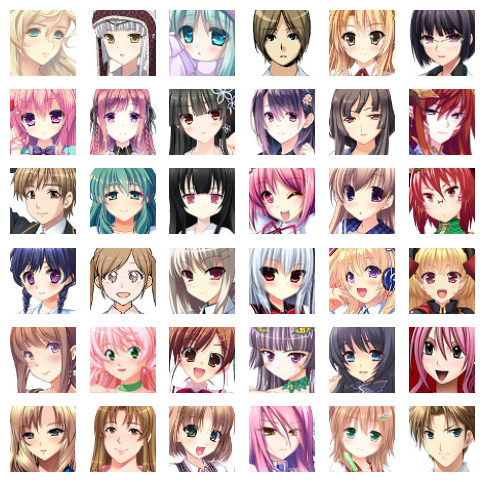

In [67]:
dataset = ImageFolder(
    anime_faces_path, transform=transforms.Compose(
        [
            transforms.ToImage(),
            transforms.ToDtype(torch.float32, scale=True),
            transforms.Resize((64, 64)),
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
        ]
    )
)

train_dataset, val_dataset = random_split(
    dataset, [0.8, 0.2], generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False, num_workers=0, pin_memory=True)

plot_dataset(train_dataset, n_cols=6, n_rows=6, denormalize=True)

In [68]:
epochs = 32
latent_dim = 128
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

generator = Generator(latent_dim)
discriminator = Discrimiminator()

g_optimizer = torch.optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
d_optimizer = torch.optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))
criterion = nn.BCELoss()

  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 1/48]
	G_Trn_Loss: 4.9603	D_Trn_Loss: 0.7634	D_Trn_Real: 0.5453	D_Trn_Fake: 0.6682	D_Trn_Acc: 82.99% 
	G_Val_Loss: 1.2894	D_Val_Loss: 1.1598	D_Val_Real: 0.5453	D_Val_Fake: 0.6682	D_Val_Acc: 69.96%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 2/48]
	G_Trn_Loss: 4.5535	D_Trn_Loss: 0.8066	D_Trn_Real: 0.5396	D_Trn_Fake: 0.8453	D_Trn_Acc: 81.48% 
	G_Val_Loss: 2.1302	D_Val_Loss: 0.9796	D_Val_Real: 0.5396	D_Val_Fake: 0.8453	D_Val_Acc: 77.24%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 3/48]
	G_Trn_Loss: 5.0867	D_Trn_Loss: 0.7298	D_Trn_Real: 0.6964	D_Trn_Fake: 0.3680	D_Trn_Acc: 83.24% 
	G_Val_Loss: 0.5011	D_Val_Loss: 1.5789	D_Val_Real: 0.6964	D_Val_Fake: 0.3680	D_Val_Acc: 50.46%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 4/48]
	G_Trn_Loss: 5.3147	D_Trn_Loss: 0.6212	D_Trn_Real: 0.4620	D_Trn_Fake: 0.6910	D_Trn_Acc: 87.16% 
	G_Val_Loss: 1.3438	D_Val_Loss: 1.4374	D_Val_Real: 0.4620	D_Val_Fake: 0.6910	D_Val_Acc: 64.81%


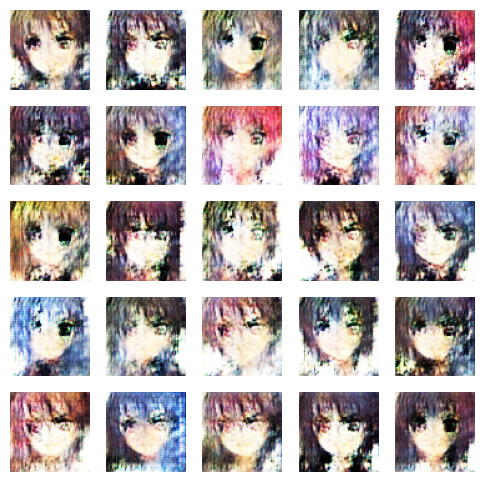

  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 5/48]
	G_Trn_Loss: 5.2504	D_Trn_Loss: 0.5662	D_Trn_Real: 0.4360	D_Trn_Fake: 0.8715	D_Trn_Acc: 88.63% 
	G_Val_Loss: 2.5077	D_Val_Loss: 1.2708	D_Val_Real: 0.4360	D_Val_Fake: 0.8715	D_Val_Acc: 68.79%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 6/48]
	G_Trn_Loss: 5.3195	D_Trn_Loss: 0.5199	D_Trn_Real: 0.4338	D_Trn_Fake: 0.9816	D_Trn_Acc: 89.95% 
	G_Val_Loss: 4.7108	D_Val_Loss: 1.1357	D_Val_Real: 0.4338	D_Val_Fake: 0.9816	D_Val_Acc: 69.76%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 7/48]
	G_Trn_Loss: 5.2896	D_Trn_Loss: 0.4618	D_Trn_Real: 0.7692	D_Trn_Fake: 0.7126	D_Trn_Acc: 91.51% 
	G_Val_Loss: 1.4391	D_Val_Loss: 0.6981	D_Val_Real: 0.7692	D_Val_Fake: 0.7126	D_Val_Acc: 86.98%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 8/48]
	G_Trn_Loss: 5.2122	D_Trn_Loss: 0.4651	D_Trn_Real: 0.5875	D_Trn_Fake: 0.8311	D_Trn_Acc: 91.17% 
	G_Val_Loss: 2.1603	D_Val_Loss: 0.8904	D_Val_Real: 0.5875	D_Val_Fake: 0.8311	D_Val_Acc: 79.66%


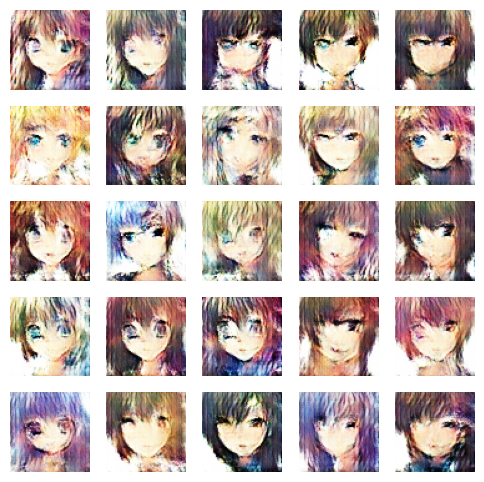

  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 9/48]
	G_Trn_Loss: 5.1242	D_Trn_Loss: 0.4324	D_Trn_Real: 0.2918	D_Trn_Fake: 0.9795	D_Trn_Acc: 91.82% 
	G_Val_Loss: 4.4873	D_Val_Loss: 1.7501	D_Val_Real: 0.2918	D_Val_Fake: 0.9795	D_Val_Acc: 60.41%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 10/48]
	G_Trn_Loss: 5.0408	D_Trn_Loss: 0.4851	D_Trn_Real: 0.7620	D_Trn_Fake: 0.8183	D_Trn_Acc: 90.41% 
	G_Val_Loss: 2.1785	D_Val_Loss: 0.5757	D_Val_Real: 0.7620	D_Val_Fake: 0.8183	D_Val_Acc: 89.51%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 11/48]
	G_Trn_Loss: 4.7651	D_Trn_Loss: 0.4510	D_Trn_Real: 0.8375	D_Trn_Fake: 0.6454	D_Trn_Acc: 91.29% 
	G_Val_Loss: 1.2488	D_Val_Loss: 0.7160	D_Val_Real: 0.8375	D_Val_Fake: 0.6454	D_Val_Acc: 84.66%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 12/48]
	G_Trn_Loss: 4.5877	D_Trn_Loss: 0.4314	D_Trn_Real: 0.6029	D_Trn_Fake: 0.8318	D_Trn_Acc: 92.07% 
	G_Val_Loss: 2.1366	D_Val_Loss: 0.8559	D_Val_Real: 0.6029	D_Val_Fake: 0.8318	D_Val_Acc: 80.63%


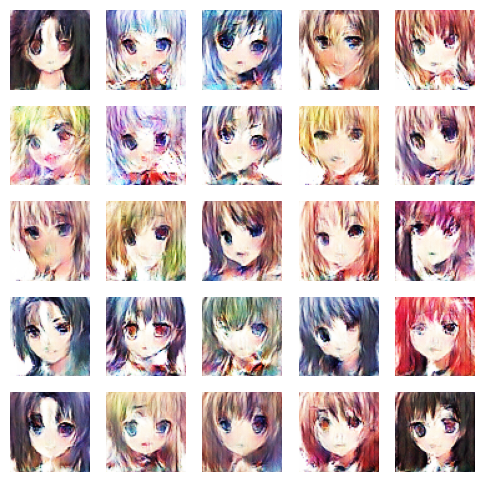

  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 13/48]
	G_Trn_Loss: 4.5382	D_Trn_Loss: 0.4497	D_Trn_Real: 0.6565	D_Trn_Fake: 0.7602	D_Trn_Acc: 91.66% 
	G_Val_Loss: 1.7119	D_Val_Loss: 0.8332	D_Val_Real: 0.6565	D_Val_Fake: 0.7602	D_Val_Acc: 82.38%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 14/48]
	G_Trn_Loss: 4.4623	D_Trn_Loss: 0.4343	D_Trn_Real: 0.5815	D_Trn_Fake: 0.8736	D_Trn_Acc: 92.50% 
	G_Val_Loss: 2.4849	D_Val_Loss: 0.8610	D_Val_Real: 0.5815	D_Val_Fake: 0.8736	D_Val_Acc: 79.75%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 15/48]
	G_Trn_Loss: 4.4256	D_Trn_Loss: 0.4459	D_Trn_Real: 0.1992	D_Trn_Fake: 0.9909	D_Trn_Acc: 91.71% 
	G_Val_Loss: 5.4158	D_Val_Loss: 2.1744	D_Val_Real: 0.1992	D_Val_Fake: 0.9909	D_Val_Acc: 55.12%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 16/48]
	G_Trn_Loss: 4.3457	D_Trn_Loss: 0.4563	D_Trn_Real: 0.3729	D_Trn_Fake: 0.8969	D_Trn_Acc: 91.66% 
	G_Val_Loss: 2.8226	D_Val_Loss: 1.4039	D_Val_Real: 0.3729	D_Val_Fake: 0.8969	D_Val_Acc: 64.12%


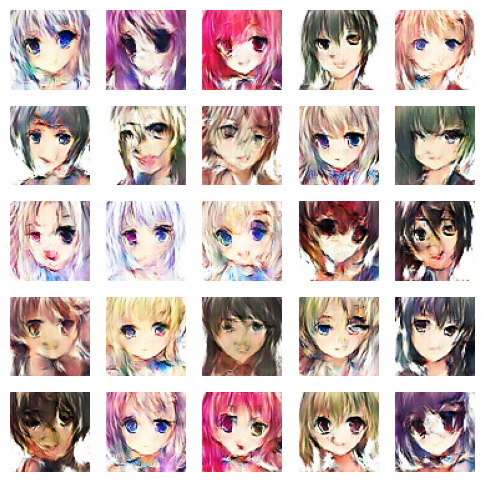

  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 17/48]
	G_Trn_Loss: 4.1768	D_Trn_Loss: 0.3879	D_Trn_Real: 0.4809	D_Trn_Fake: 0.9149	D_Trn_Acc: 93.61% 
	G_Val_Loss: 3.0105	D_Val_Loss: 1.0445	D_Val_Real: 0.4809	D_Val_Fake: 0.9149	D_Val_Acc: 73.08%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 18/48]
	G_Trn_Loss: 4.2845	D_Trn_Loss: 0.4187	D_Trn_Real: 0.7742	D_Trn_Fake: 0.6813	D_Trn_Acc: 92.27% 
	G_Val_Loss: 1.5413	D_Val_Loss: 0.8162	D_Val_Real: 0.7742	D_Val_Fake: 0.6813	D_Val_Acc: 81.61%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 19/48]
	G_Trn_Loss: 4.2008	D_Trn_Loss: 0.3850	D_Trn_Real: 0.5532	D_Trn_Fake: 0.9103	D_Trn_Acc: 93.72% 
	G_Val_Loss: 2.8561	D_Val_Loss: 0.8322	D_Val_Real: 0.5532	D_Val_Fake: 0.9103	D_Val_Acc: 78.61%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 20/48]
	G_Trn_Loss: 4.1006	D_Trn_Loss: 0.4382	D_Trn_Real: 0.6043	D_Trn_Fake: 0.8528	D_Trn_Acc: 93.17% 
	G_Val_Loss: 2.3177	D_Val_Loss: 0.7952	D_Val_Real: 0.6043	D_Val_Fake: 0.8528	D_Val_Acc: 82.33%


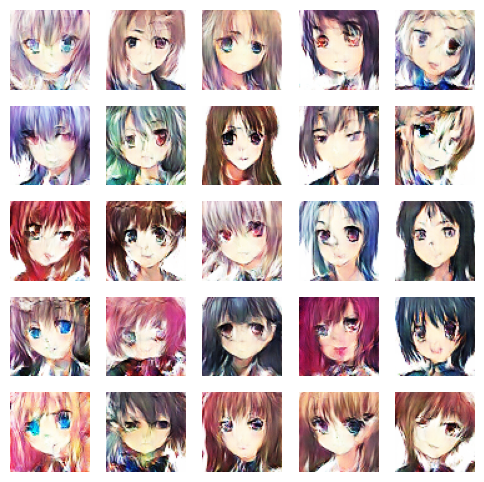

  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 21/48]
	G_Trn_Loss: 4.1229	D_Trn_Loss: 0.3509	D_Trn_Real: 0.2119	D_Trn_Fake: 0.9820	D_Trn_Acc: 94.56% 
	G_Val_Loss: 4.8728	D_Val_Loss: 2.1279	D_Val_Real: 0.2119	D_Val_Fake: 0.9820	D_Val_Acc: 55.22%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 22/48]
	G_Trn_Loss: 4.1235	D_Trn_Loss: 0.3911	D_Trn_Real: 0.7803	D_Trn_Fake: 0.6203	D_Trn_Acc: 93.34% 
	G_Val_Loss: 1.2814	D_Val_Loss: 0.8998	D_Val_Real: 0.7803	D_Val_Fake: 0.6203	D_Val_Acc: 78.40%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 23/48]
	G_Trn_Loss: 4.3185	D_Trn_Loss: 0.3706	D_Trn_Real: 0.9034	D_Trn_Fake: 0.6254	D_Trn_Acc: 93.64% 
	G_Val_Loss: 1.2224	D_Val_Loss: 0.6819	D_Val_Real: 0.9034	D_Val_Fake: 0.6254	D_Val_Acc: 84.34%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 24/48]
	G_Trn_Loss: 4.0563	D_Trn_Loss: 0.3972	D_Trn_Real: 0.4054	D_Trn_Fake: 0.9369	D_Trn_Acc: 94.27% 
	G_Val_Loss: 3.3740	D_Val_Loss: 1.2464	D_Val_Real: 0.4054	D_Val_Fake: 0.9369	D_Val_Acc: 67.23%


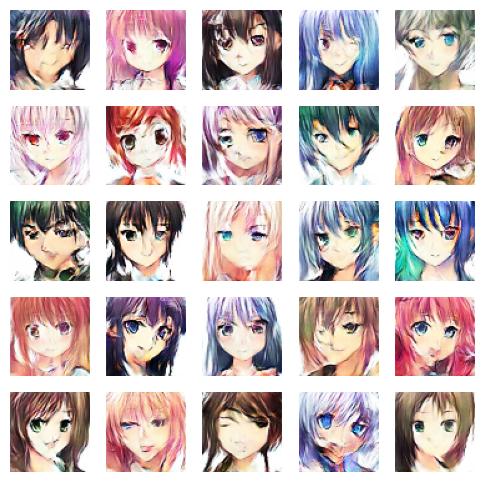

  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 25/48]
	G_Trn_Loss: 4.1848	D_Trn_Loss: 0.3467	D_Trn_Real: 0.7066	D_Trn_Fake: 0.8176	D_Trn_Acc: 94.65% 
	G_Val_Loss: 2.1461	D_Val_Loss: 0.6547	D_Val_Real: 0.7066	D_Val_Fake: 0.8176	D_Val_Acc: 87.70%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 26/48]
	G_Trn_Loss: 4.1427	D_Trn_Loss: 0.3722	D_Trn_Real: 0.7591	D_Trn_Fake: 0.7192	D_Trn_Acc: 94.46% 
	G_Val_Loss: 1.7610	D_Val_Loss: 0.7869	D_Val_Real: 0.7591	D_Val_Fake: 0.7192	D_Val_Acc: 82.08%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 27/48]
	G_Trn_Loss: 4.0854	D_Trn_Loss: 0.3197	D_Trn_Real: 0.6876	D_Trn_Fake: 0.8387	D_Trn_Acc: 95.23% 
	G_Val_Loss: 2.2969	D_Val_Loss: 0.6755	D_Val_Real: 0.6876	D_Val_Fake: 0.8387	D_Val_Acc: 85.98%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 28/48]
	G_Trn_Loss: 4.1800	D_Trn_Loss: 0.3644	D_Trn_Real: 0.6662	D_Trn_Fake: 0.9525	D_Trn_Acc: 94.58% 
	G_Val_Loss: 4.2954	D_Val_Loss: 0.6112	D_Val_Real: 0.6662	D_Val_Fake: 0.9525	D_Val_Acc: 85.75%


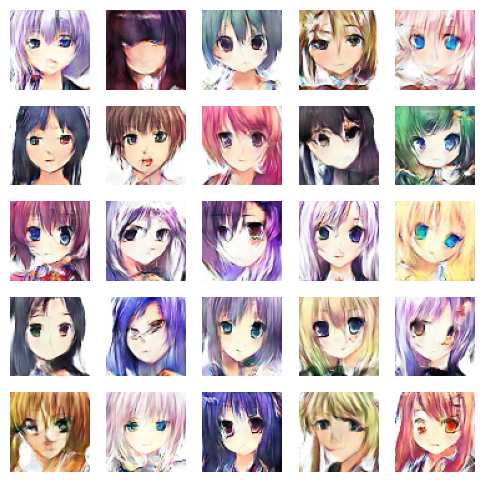

  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 29/48]
	G_Trn_Loss: 4.1231	D_Trn_Loss: 0.3449	D_Trn_Real: 0.6432	D_Trn_Fake: 0.8471	D_Trn_Acc: 95.15% 
	G_Val_Loss: 2.3555	D_Val_Loss: 0.7399	D_Val_Real: 0.6432	D_Val_Fake: 0.8471	D_Val_Acc: 83.34%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 30/48]
	G_Trn_Loss: 4.1800	D_Trn_Loss: 0.2914	D_Trn_Real: 0.9636	D_Trn_Fake: 0.5822	D_Trn_Acc: 96.06% 
	G_Val_Loss: 1.4273	D_Val_Loss: 0.9579	D_Val_Real: 0.9636	D_Val_Fake: 0.5822	D_Val_Acc: 79.86%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 31/48]
	G_Trn_Loss: 4.5016	D_Trn_Loss: 0.2769	D_Trn_Real: 0.6134	D_Trn_Fake: 0.8821	D_Trn_Acc: 95.99% 
	G_Val_Loss: 2.6272	D_Val_Loss: 0.7551	D_Val_Real: 0.6134	D_Val_Fake: 0.8821	D_Val_Acc: 82.90%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 32/48]
	G_Trn_Loss: 4.3591	D_Trn_Loss: 0.3880	D_Trn_Real: 0.7020	D_Trn_Fake: 0.8564	D_Trn_Acc: 94.35% 
	G_Val_Loss: 2.3847	D_Val_Loss: 0.6219	D_Val_Real: 0.7020	D_Val_Fake: 0.8564	D_Val_Acc: 88.22%


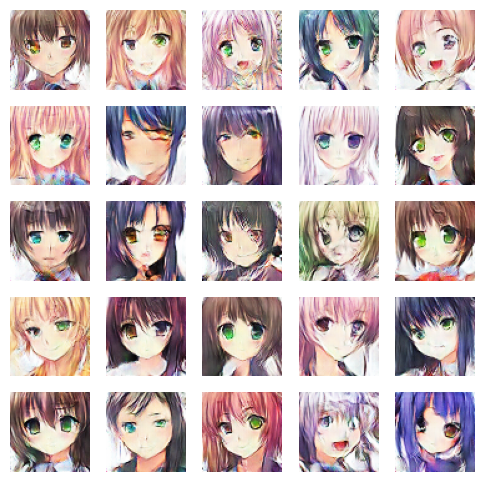

  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 33/48]
	G_Trn_Loss: 4.1917	D_Trn_Loss: 0.2790	D_Trn_Real: 0.5952	D_Trn_Fake: 0.9130	D_Trn_Acc: 96.70% 
	G_Val_Loss: 3.0178	D_Val_Loss: 0.8056	D_Val_Real: 0.5952	D_Val_Fake: 0.9130	D_Val_Acc: 80.94%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 34/48]
	G_Trn_Loss: 4.4916	D_Trn_Loss: 0.2886	D_Trn_Real: 0.5019	D_Trn_Fake: 0.9116	D_Trn_Acc: 95.93% 
	G_Val_Loss: 3.0534	D_Val_Loss: 1.0348	D_Val_Real: 0.5019	D_Val_Fake: 0.9116	D_Val_Acc: 74.63%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 35/48]
	G_Trn_Loss: 4.5614	D_Trn_Loss: 0.2474	D_Trn_Real: 0.5163	D_Trn_Fake: 0.8476	D_Trn_Acc: 96.62% 
	G_Val_Loss: 2.3736	D_Val_Loss: 1.1418	D_Val_Real: 0.5163	D_Val_Fake: 0.8476	D_Val_Acc: 74.30%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 36/48]
	G_Trn_Loss: 4.3524	D_Trn_Loss: 0.2971	D_Trn_Real: 0.3911	D_Trn_Fake: 0.9139	D_Trn_Acc: 96.23% 
	G_Val_Loss: 3.1601	D_Val_Loss: 1.4838	D_Val_Real: 0.3911	D_Val_Fake: 0.9139	D_Val_Acc: 67.07%


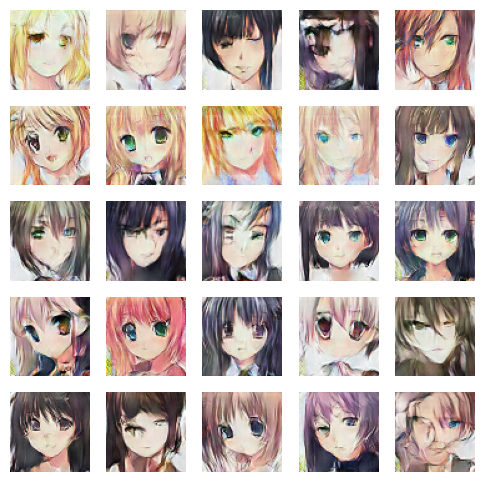

  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 37/48]
	G_Trn_Loss: 4.4796	D_Trn_Loss: 0.2735	D_Trn_Real: 0.5855	D_Trn_Fake: 0.8071	D_Trn_Acc: 95.94% 
	G_Val_Loss: 2.1822	D_Val_Loss: 1.0560	D_Val_Real: 0.5855	D_Val_Fake: 0.8071	D_Val_Acc: 76.44%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 38/48]
	G_Trn_Loss: 4.4512	D_Trn_Loss: 0.2628	D_Trn_Real: 0.5991	D_Trn_Fake: 0.8580	D_Trn_Acc: 96.78% 
	G_Val_Loss: 2.4571	D_Val_Loss: 0.8861	D_Val_Real: 0.5991	D_Val_Fake: 0.8580	D_Val_Acc: 80.01%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 39/48]
	G_Trn_Loss: 4.2993	D_Trn_Loss: 0.2236	D_Trn_Real: 0.7124	D_Trn_Fake: 0.8315	D_Trn_Acc: 97.74% 
	G_Val_Loss: 2.2250	D_Val_Loss: 0.6764	D_Val_Real: 0.7124	D_Val_Fake: 0.8315	D_Val_Acc: 86.60%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 40/48]
	G_Trn_Loss: 4.4106	D_Trn_Loss: 0.3396	D_Trn_Real: 0.3140	D_Trn_Fake: 0.9431	D_Trn_Acc: 95.71% 
	G_Val_Loss: 3.6248	D_Val_Loss: 1.7692	D_Val_Real: 0.3140	D_Val_Fake: 0.9431	D_Val_Acc: 62.17%


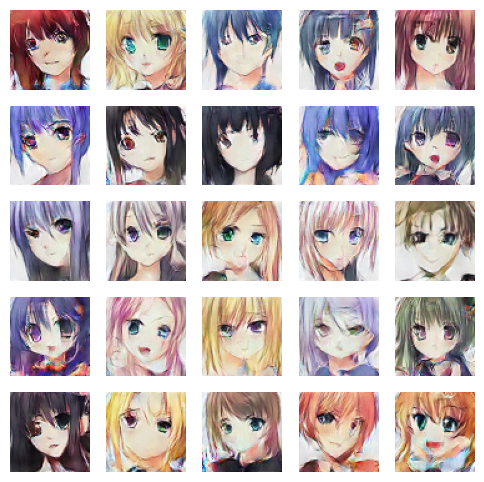

  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 41/48]
	G_Trn_Loss: 4.3974	D_Trn_Loss: 0.2273	D_Trn_Real: 0.8202	D_Trn_Fake: 0.7102	D_Trn_Acc: 97.45% 
	G_Val_Loss: 1.5831	D_Val_Loss: 0.6652	D_Val_Real: 0.8202	D_Val_Fake: 0.7102	D_Val_Acc: 85.81%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 42/48]
	G_Trn_Loss: 4.5411	D_Trn_Loss: 0.2304	D_Trn_Real: 0.7323	D_Trn_Fake: 0.8549	D_Trn_Acc: 96.88% 
	G_Val_Loss: 2.4899	D_Val_Loss: 0.6004	D_Val_Real: 0.7323	D_Val_Fake: 0.8549	D_Val_Acc: 88.72%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 43/48]
	G_Trn_Loss: 4.5267	D_Trn_Loss: 0.1739	D_Trn_Real: 0.6833	D_Trn_Fake: 0.8738	D_Trn_Acc: 98.19% 
	G_Val_Loss: 2.6052	D_Val_Loss: 0.6745	D_Val_Real: 0.6833	D_Val_Fake: 0.8738	D_Val_Acc: 86.43%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 44/48]
	G_Trn_Loss: 4.6132	D_Trn_Loss: 0.3423	D_Trn_Real: 0.3447	D_Trn_Fake: 0.8824	D_Trn_Acc: 96.02% 
	G_Val_Loss: 2.8466	D_Val_Loss: 1.8392	D_Val_Real: 0.3447	D_Val_Fake: 0.8824	D_Val_Acc: 63.11%


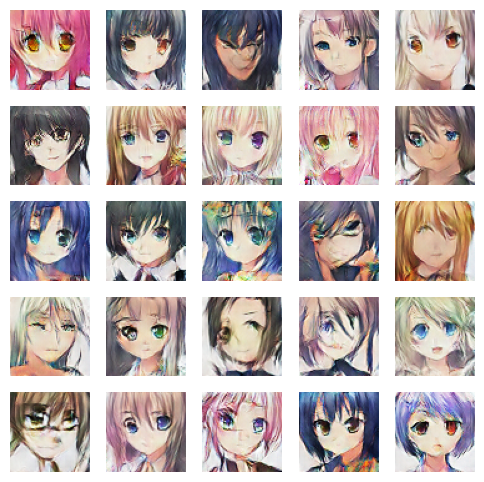

  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 45/48]
	G_Trn_Loss: 4.4603	D_Trn_Loss: 0.1629	D_Trn_Real: 0.4509	D_Trn_Fake: 0.9147	D_Trn_Acc: 98.68% 
	G_Val_Loss: 3.1615	D_Val_Loss: 1.2512	D_Val_Real: 0.4509	D_Val_Fake: 0.9147	D_Val_Acc: 70.65%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 46/48]
	G_Trn_Loss: 4.7993	D_Trn_Loss: 0.3036	D_Trn_Real: 0.7344	D_Trn_Fake: 0.7952	D_Trn_Acc: 95.65% 
	G_Val_Loss: 2.0752	D_Val_Loss: 0.7042	D_Val_Real: 0.7344	D_Val_Fake: 0.7952	D_Val_Acc: 85.58%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 47/48]
	G_Trn_Loss: 4.5119	D_Trn_Loss: 0.0853	D_Trn_Real: 0.6411	D_Trn_Fake: 0.8975	D_Trn_Acc: 99.75% 
	G_Val_Loss: 2.8915	D_Val_Loss: 0.7706	D_Val_Real: 0.6411	D_Val_Fake: 0.8975	D_Val_Acc: 83.68%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 48/48]
	G_Trn_Loss: 4.6052	D_Trn_Loss: 0.2705	D_Trn_Real: 0.5529	D_Trn_Fake: 0.8845	D_Trn_Acc: 96.84% 
	G_Val_Loss: 2.7347	D_Val_Loss: 1.0274	D_Val_Real: 0.5529	D_Val_Fake: 0.8845	D_Val_Acc: 77.64%


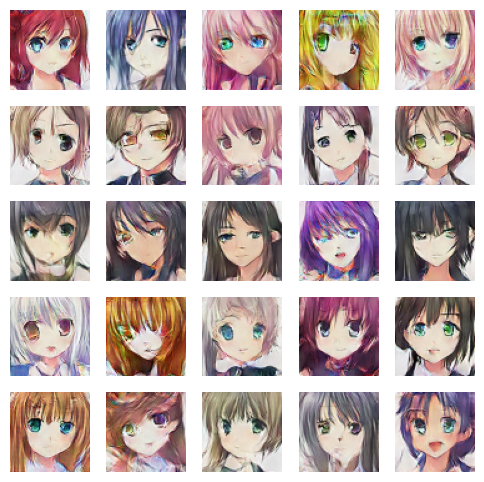

In [ ]:
train_stats, val_stats = train(
    generator,
    discriminator,
    train_loader,
    val_loader,
    g_optimizer,
    d_optimizer,
    criterion,
    device,
    epochs=epochs,
    plot_frequency=4,
)

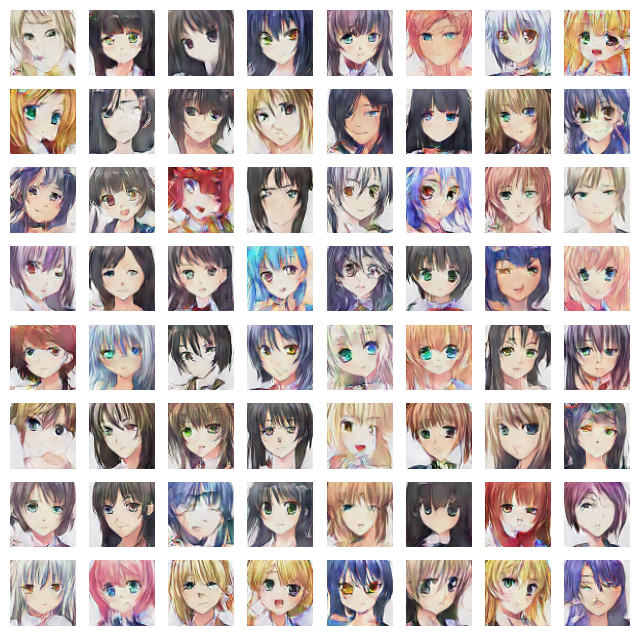

In [70]:
plot_generated_images(generator, device=device, num_images=64, denormalize=True, figsize=(8, 8))

# Exercícios

## Exercício 1

Treine uma GAN no dataset [Cebradata](https://www.kaggle.com/alsaniipe/cebradata). O dataset contém imagens de rostos de celebridades e foi baixado junto com o notebook.

<details>
<summary>Dica:</summary>

A maior diferença entre o Anime Faces e o CelebA é o tamanho das imagens. O CelebA contém imagens de 218x178 pixels, enquanto o Anime Faces contém imagens de 64x64 pixels. Portanto, você precisará ajustar o tamanho das imagens no modelo.

</details>

In [96]:
cebradata_path = './data/cebradata/'

In [97]:
celeb_faces = ImageFolder(
    cebradata_path,
    transform=transforms.Compose(
        [
            transforms.ToImage(),
            transforms.ToDtype(torch.float32, scale=True),
            # center crop images to 64x64 so they are closer to the camera
            transforms.Resize((96, 96)),
            transforms.CenterCrop((64, 64)),
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
        ]
    ),
)

Number of samples: 202599
Sample shape: torch.Size([3, 64, 64])


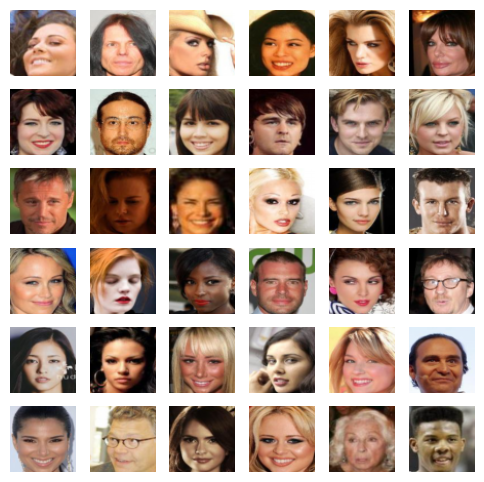

In [98]:
plot_dataset(celeb_faces, n_cols=6, n_rows=6, denormalize=True)

Number of samples: 162080
Sample shape: torch.Size([3, 64, 64])


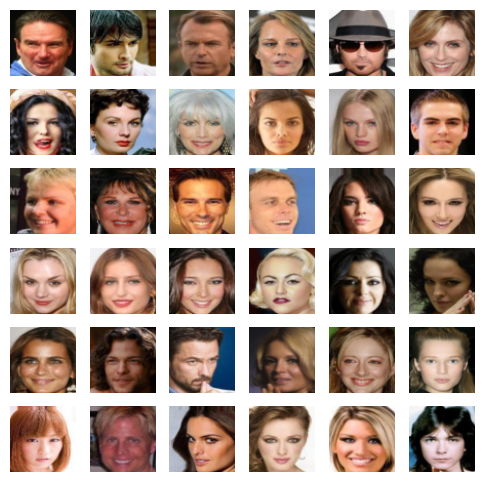

In [99]:
train_dataset, val_dataset = random_split(
    celeb_faces, [0.8, 0.2], generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False, num_workers=2, pin_memory=True)

plot_dataset(train_dataset, n_cols=6, n_rows=6, denormalize=True)

In [100]:
epochs = 24
latent_dim = 128
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

generator = Generator(latent_dim)
discriminator = Discrimiminator()

g_optimizer = torch.optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
d_optimizer = torch.optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))
criterion = nn.BCELoss()

  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 1/32]
	G_Trn_Loss: 4.1829	D_Trn_Loss: 0.6510	D_Trn_Real: 0.6576	D_Trn_Fake: 0.6351	D_Trn_Acc: 87.21% 
	G_Val_Loss: 1.1173	D_Val_Loss: 0.9732	D_Val_Real: 0.6576	D_Val_Fake: 0.6351	D_Val_Acc: 78.76%


  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 2/32]
	G_Trn_Loss: 3.1917	D_Trn_Loss: 0.6533	D_Trn_Real: 0.6637	D_Trn_Fake: 0.6388	D_Trn_Acc: 86.53% 
	G_Val_Loss: 1.2113	D_Val_Loss: 1.0173	D_Val_Real: 0.6637	D_Val_Fake: 0.6388	D_Val_Acc: 75.07%


  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 3/32]
	G_Trn_Loss: 3.2315	D_Trn_Loss: 0.5888	D_Trn_Real: 0.7550	D_Trn_Fake: 0.8139	D_Trn_Acc: 88.73% 
	G_Val_Loss: 2.1622	D_Val_Loss: 0.5771	D_Val_Real: 0.7550	D_Val_Fake: 0.8139	D_Val_Acc: 90.25%


  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 4/32]
	G_Trn_Loss: 3.4963	D_Trn_Loss: 0.5056	D_Trn_Real: 0.5039	D_Trn_Fake: 0.8429	D_Trn_Acc: 90.96% 
	G_Val_Loss: 2.1776	D_Val_Loss: 1.0174	D_Val_Real: 0.5039	D_Val_Fake: 0.8429	D_Val_Acc: 73.96%


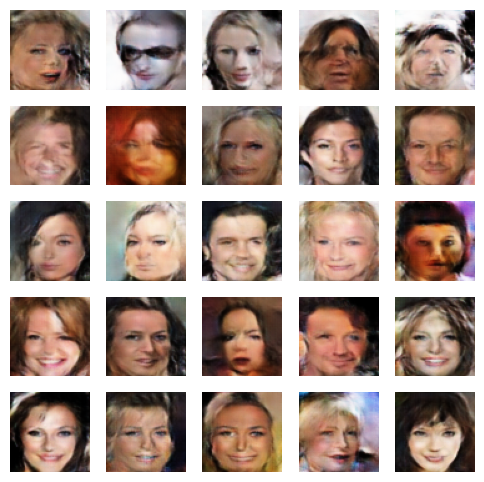

  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 5/32]
	G_Trn_Loss: 3.8122	D_Trn_Loss: 0.4385	D_Trn_Real: 0.6127	D_Trn_Fake: 0.8249	D_Trn_Acc: 92.98% 
	G_Val_Loss: 2.4176	D_Val_Loss: 0.9230	D_Val_Real: 0.6127	D_Val_Fake: 0.8249	D_Val_Acc: 78.30%


  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 6/32]
	G_Trn_Loss: 4.1537	D_Trn_Loss: 0.3563	D_Trn_Real: 0.6758	D_Trn_Fake: 0.8856	D_Trn_Acc: 94.48% 
	G_Val_Loss: 2.6136	D_Val_Loss: 0.6197	D_Val_Real: 0.6758	D_Val_Fake: 0.8856	D_Val_Acc: 86.92%


  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 7/32]
	G_Trn_Loss: 4.4777	D_Trn_Loss: 0.3171	D_Trn_Real: 0.6236	D_Trn_Fake: 0.8318	D_Trn_Acc: 95.44% 
	G_Val_Loss: 2.3776	D_Val_Loss: 0.8668	D_Val_Real: 0.6236	D_Val_Fake: 0.8318	D_Val_Acc: 79.92%


  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 8/32]
	G_Trn_Loss: 4.5840	D_Trn_Loss: 0.3262	D_Trn_Real: 0.9391	D_Trn_Fake: 0.5627	D_Trn_Acc: 95.20% 
	G_Val_Loss: 1.1155	D_Val_Loss: 0.8034	D_Val_Real: 0.9391	D_Val_Fake: 0.5627	D_Val_Acc: 78.76%


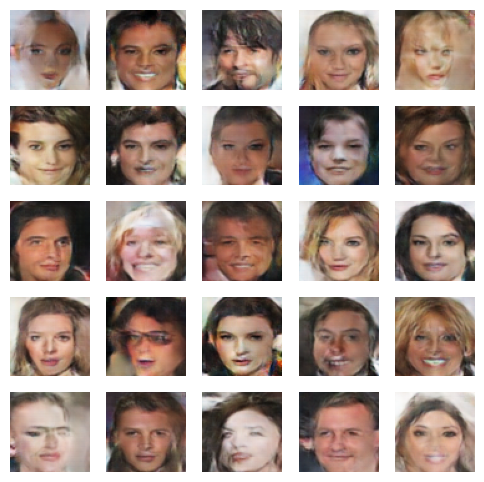

  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 9/32]
	G_Trn_Loss: 4.6325	D_Trn_Loss: 0.2944	D_Trn_Real: 0.7860	D_Trn_Fake: 0.8095	D_Trn_Acc: 95.52% 
	G_Val_Loss: 2.1468	D_Val_Loss: 0.5657	D_Val_Real: 0.7860	D_Val_Fake: 0.8095	D_Val_Acc: 89.39%


  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 10/32]
	G_Trn_Loss: 4.5435	D_Trn_Loss: 0.3300	D_Trn_Real: 0.6859	D_Trn_Fake: 0.9836	D_Trn_Acc: 94.86% 
	G_Val_Loss: 4.9202	D_Val_Loss: 0.5182	D_Val_Real: 0.6859	D_Val_Fake: 0.9836	D_Val_Acc: 87.44%


  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 11/32]
	G_Trn_Loss: 4.5240	D_Trn_Loss: 0.3267	D_Trn_Real: 0.6556	D_Trn_Fake: 0.9917	D_Trn_Acc: 94.86% 
	G_Val_Loss: 6.0761	D_Val_Loss: 0.6159	D_Val_Real: 0.6556	D_Val_Fake: 0.9917	D_Val_Acc: 84.51%


  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 12/32]
	G_Trn_Loss: 4.7955	D_Trn_Loss: 0.2880	D_Trn_Real: 0.7135	D_Trn_Fake: 0.6928	D_Trn_Acc: 95.29% 
	G_Val_Loss: 1.8308	D_Val_Loss: 1.0364	D_Val_Real: 0.7135	D_Val_Fake: 0.6928	D_Val_Acc: 75.15%


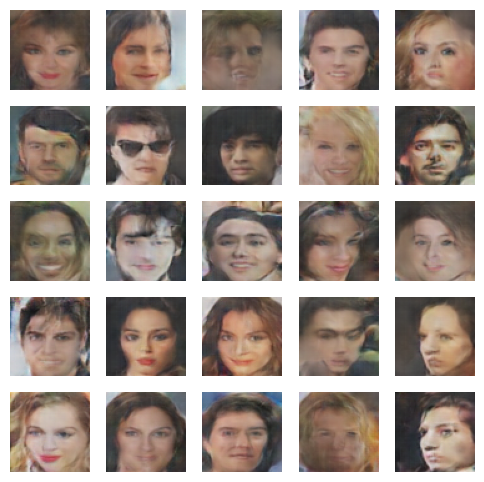

  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 13/32]
	G_Trn_Loss: 5.0175	D_Trn_Loss: 0.2559	D_Trn_Real: 0.7832	D_Trn_Fake: 0.8530	D_Trn_Acc: 95.87% 
	G_Val_Loss: 2.5355	D_Val_Loss: 0.5269	D_Val_Real: 0.7832	D_Val_Fake: 0.8530	D_Val_Acc: 90.19%


  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 14/32]
	G_Trn_Loss: 4.8343	D_Trn_Loss: 0.3120	D_Trn_Real: 0.5243	D_Trn_Fake: 0.8321	D_Trn_Acc: 95.25% 
	G_Val_Loss: 2.2692	D_Val_Loss: 1.2343	D_Val_Real: 0.5243	D_Val_Fake: 0.8321	D_Val_Acc: 74.36%


  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 15/32]
	G_Trn_Loss: 5.0600	D_Trn_Loss: 0.2665	D_Trn_Real: 0.8746	D_Trn_Fake: 0.8321	D_Trn_Acc: 95.69% 
	G_Val_Loss: 2.3248	D_Val_Loss: 0.4042	D_Val_Real: 0.8746	D_Val_Fake: 0.8321	D_Val_Acc: 93.83%


  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 16/32]
	G_Trn_Loss: 5.1317	D_Trn_Loss: 0.2332	D_Trn_Real: 0.4840	D_Trn_Fake: 0.9707	D_Trn_Acc: 96.52% 
	G_Val_Loss: 4.2760	D_Val_Loss: 1.1585	D_Val_Real: 0.4840	D_Val_Fake: 0.9707	D_Val_Acc: 73.14%


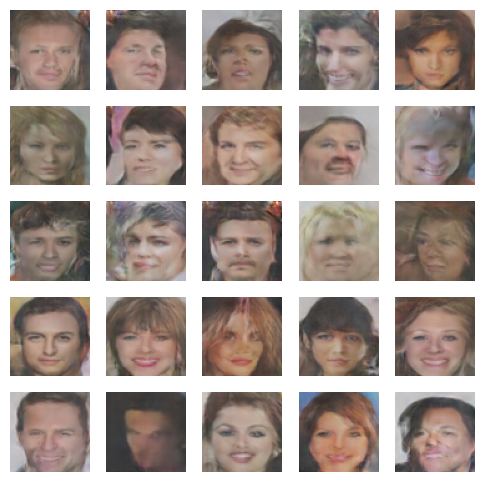

  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 17/32]
	G_Trn_Loss: 5.0082	D_Trn_Loss: 0.2667	D_Trn_Real: 0.6741	D_Trn_Fake: 0.9408	D_Trn_Acc: 95.81% 
	G_Val_Loss: 3.8321	D_Val_Loss: 0.6952	D_Val_Real: 0.6741	D_Val_Fake: 0.9408	D_Val_Acc: 85.62%


  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 18/32]
	G_Trn_Loss: 5.1434	D_Trn_Loss: 0.2990	D_Trn_Real: 0.7836	D_Trn_Fake: 0.9411	D_Trn_Acc: 95.45% 
	G_Val_Loss: 3.5047	D_Val_Loss: 0.4105	D_Val_Real: 0.7836	D_Val_Fake: 0.9411	D_Val_Acc: 92.05%


  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 19/32]
	G_Trn_Loss: 5.2309	D_Trn_Loss: 0.2157	D_Trn_Real: 0.8210	D_Trn_Fake: 0.9721	D_Trn_Acc: 96.67% 
	G_Val_Loss: 4.3020	D_Val_Loss: 0.3087	D_Val_Real: 0.8210	D_Val_Fake: 0.9721	D_Val_Acc: 94.02%


  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 20/32]
	G_Trn_Loss: 5.1854	D_Trn_Loss: 0.2492	D_Trn_Real: 0.7973	D_Trn_Fake: 0.9811	D_Trn_Acc: 96.24% 
	G_Val_Loss: 4.7758	D_Val_Loss: 0.3519	D_Val_Real: 0.7973	D_Val_Fake: 0.9811	D_Val_Acc: 92.67%


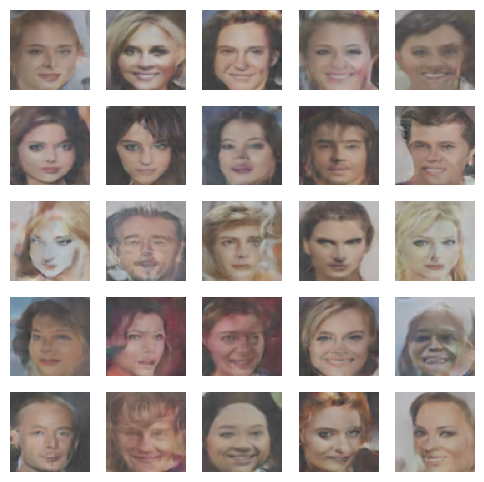

  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 21/32]
	G_Trn_Loss: 5.3853	D_Trn_Loss: 0.2139	D_Trn_Real: 0.8016	D_Trn_Fake: 0.7217	D_Trn_Acc: 96.62% 
	G_Val_Loss: 1.6417	D_Val_Loss: 0.7230	D_Val_Real: 0.8016	D_Val_Fake: 0.7217	D_Val_Acc: 84.90%


  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 22/32]
	G_Trn_Loss: 5.2858	D_Trn_Loss: 0.1969	D_Trn_Real: 0.9307	D_Trn_Fake: 0.6852	D_Trn_Acc: 97.12% 
	G_Val_Loss: 2.0406	D_Val_Loss: 0.7331	D_Val_Real: 0.9307	D_Val_Fake: 0.6852	D_Val_Acc: 83.70%


  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 23/32]
	G_Trn_Loss: 5.1283	D_Trn_Loss: 0.2118	D_Trn_Real: 0.9268	D_Trn_Fake: 0.9760	D_Trn_Acc: 96.73% 
	G_Val_Loss: 4.5914	D_Val_Loss: 0.1390	D_Val_Real: 0.9268	D_Val_Fake: 0.9760	D_Val_Acc: 98.04%


  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 24/32]
	G_Trn_Loss: 5.1930	D_Trn_Loss: 0.2370	D_Trn_Real: 0.7180	D_Trn_Fake: 0.9042	D_Trn_Acc: 96.46% 
	G_Val_Loss: 2.9247	D_Val_Loss: 0.6500	D_Val_Real: 0.7180	D_Val_Fake: 0.9042	D_Val_Acc: 86.61%


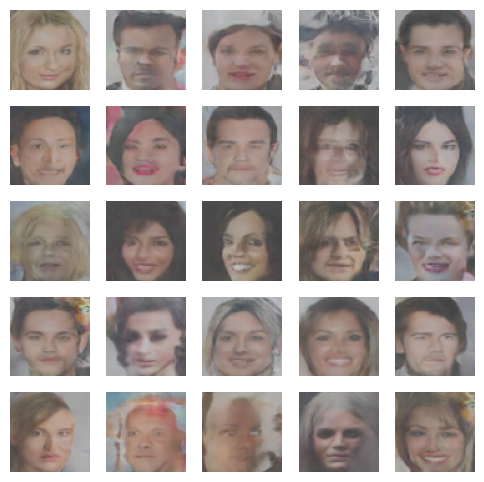

  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 25/32]
	G_Trn_Loss: 5.1585	D_Trn_Loss: 0.2109	D_Trn_Real: 0.9035	D_Trn_Fake: 0.7778	D_Trn_Acc: 96.75% 
	G_Val_Loss: 1.8991	D_Val_Loss: 0.4299	D_Val_Real: 0.9035	D_Val_Fake: 0.7778	D_Val_Acc: 92.81%


  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 26/32]
	G_Trn_Loss: 4.8332	D_Trn_Loss: 0.2789	D_Trn_Real: 0.7916	D_Trn_Fake: 0.8969	D_Trn_Acc: 96.12% 
	G_Val_Loss: 2.9775	D_Val_Loss: 0.5076	D_Val_Real: 0.7916	D_Val_Fake: 0.8969	D_Val_Acc: 91.35%


  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 27/32]
	G_Trn_Loss: 5.2067	D_Trn_Loss: 0.2016	D_Trn_Real: 0.8865	D_Trn_Fake: 0.9205	D_Trn_Acc: 97.11% 
	G_Val_Loss: 3.2138	D_Val_Loss: 0.2562	D_Val_Real: 0.8865	D_Val_Fake: 0.9205	D_Val_Acc: 96.46%


  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 28/32]
	G_Trn_Loss: 5.0570	D_Trn_Loss: 0.2367	D_Trn_Real: 0.8303	D_Trn_Fake: 0.8782	D_Trn_Acc: 96.66% 
	G_Val_Loss: 2.7023	D_Val_Loss: 0.4272	D_Val_Real: 0.8303	D_Val_Fake: 0.8782	D_Val_Acc: 92.78%


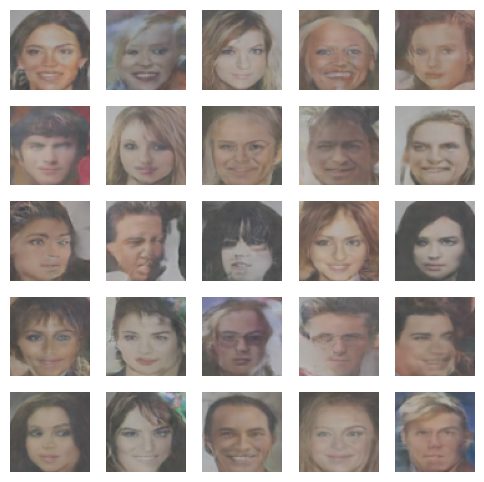

  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 29/32]
	G_Trn_Loss: 5.0252	D_Trn_Loss: 0.2353	D_Trn_Real: 0.9560	D_Trn_Fake: 0.7446	D_Trn_Acc: 96.59% 
	G_Val_Loss: 1.6982	D_Val_Loss: 0.3996	D_Val_Real: 0.9560	D_Val_Fake: 0.7446	D_Val_Acc: 93.17%


  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 30/32]
	G_Trn_Loss: 4.9905	D_Trn_Loss: 0.2332	D_Trn_Real: 0.7808	D_Trn_Fake: 0.9133	D_Trn_Acc: 96.57% 
	G_Val_Loss: 3.0147	D_Val_Loss: 0.4956	D_Val_Real: 0.7808	D_Val_Fake: 0.9133	D_Val_Acc: 91.05%


  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 31/32]
	G_Trn_Loss: 5.2427	D_Trn_Loss: 0.1997	D_Trn_Real: 0.7265	D_Trn_Fake: 0.8818	D_Trn_Acc: 97.10% 
	G_Val_Loss: 2.6519	D_Val_Loss: 0.6638	D_Val_Real: 0.7265	D_Val_Fake: 0.8818	D_Val_Acc: 87.13%


  0%|          | 0/1267 [00:00<?, ?batch/s]

[Epoch 32/32]
	G_Trn_Loss: 5.1659	D_Trn_Loss: 0.2246	D_Trn_Real: 0.8334	D_Trn_Fake: 0.8699	D_Trn_Acc: 96.77% 
	G_Val_Loss: 2.6415	D_Val_Loss: 0.4328	D_Val_Real: 0.8334	D_Val_Fake: 0.8699	D_Val_Acc: 93.04%


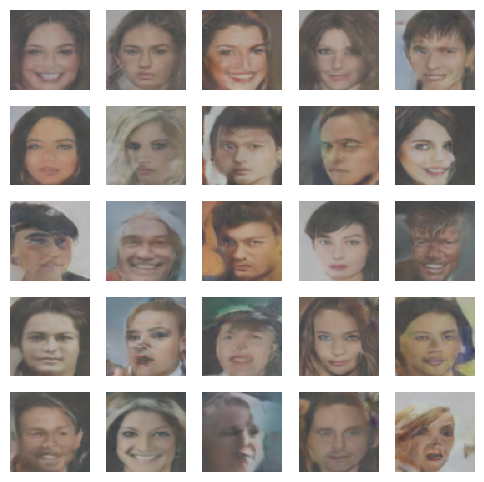

In [101]:
g_stats, d_stats = train(
    generator,
    discriminator,
    train_loader,
    val_loader,
    g_optimizer,
    d_optimizer,
    criterion,
    device,
    epochs=epochs,
    plot_frequency=4,
)

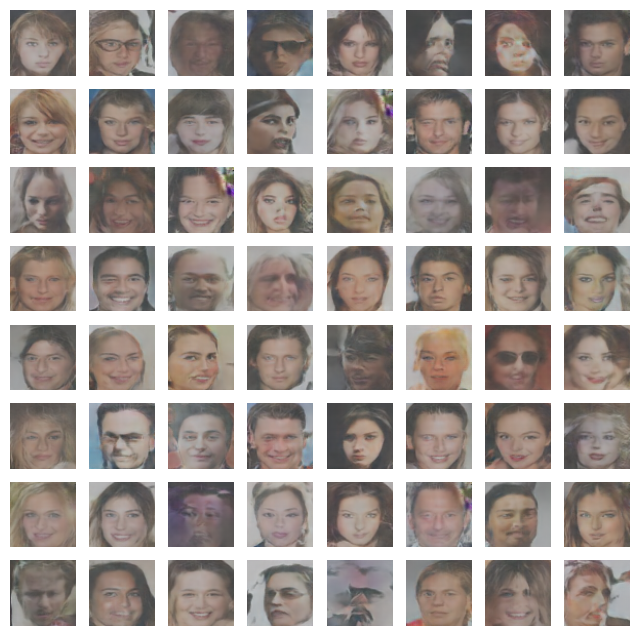

In [102]:
plot_generated_images(generator, device=device, num_images=64, denormalize=True, figsize=(8, 8))

## Exercício 2

Uma patchGAN é um discriminador introduzido no artigo [Image-to-Image Translation with Conditional Adversarial Networks](https://arxiv.org/abs/1611.07004). A ideia é substituir a última camada convolucional do discriminador por uma camada convolucional que produz um mapa de ativação NxN, onde temos um valor para cada patch da imagem de entrada. Isso permite que o discriminador se concentre em detalhes locais da imagem, em vez de apenas na imagem como um todo.

Implemente uma patchGAN no discriminador da GAN e treine o modelo com o dataset que preferir.

<details>
<summary>Dica:</summary>

A função `train` utilizada anteriormente já está adaptada para lidar com esse tipo de discriminador. Você só precisa implementar a patchGAN no discriminador.

</details>

In [185]:
class PatchDiscriminator(nn.Module):
    def __init__(self, in_channels=3):
        super(PatchDiscriminator, self).__init__()

        # TODO: Defina uma rede que retorne processe uma imagem de 64x64 e retorne
        # 8x8 predições
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, 64, kernel_size=4, stride=2, padding=1, bias=False), # (64, 32, 32)
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),  # (128, 16, 16)
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),
            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1, bias=False),  # (256, 8, 8)
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2),
            nn.Conv2d(256, 1, kernel_size=1, bias=False),  # (1, 8, 8)
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x)

In [186]:
patch_discriminator = PatchDiscriminator()
patch_discriminator.to(device)
summary(patch_discriminator, (128, 3, 64, 64))

Layer (type:depth-idx)                   Output Shape              Param #
PatchDiscriminator                       [128, 1, 8, 8]            --
├─Sequential: 1-1                        [128, 1, 8, 8]            --
│    └─Conv2d: 2-1                       [128, 64, 32, 32]         3,072
│    └─BatchNorm2d: 2-2                  [128, 64, 32, 32]         128
│    └─LeakyReLU: 2-3                    [128, 64, 32, 32]         --
│    └─Conv2d: 2-4                       [128, 128, 16, 16]        131,072
│    └─BatchNorm2d: 2-5                  [128, 128, 16, 16]        256
│    └─LeakyReLU: 2-6                    [128, 128, 16, 16]        --
│    └─Conv2d: 2-7                       [128, 256, 8, 8]          524,288
│    └─BatchNorm2d: 2-8                  [128, 256, 8, 8]          512
│    └─LeakyReLU: 2-9                    [128, 256, 8, 8]          --
│    └─Conv2d: 2-10                      [128, 1, 8, 8]            256
│    └─Sigmoid: 2-11                     [128, 1, 8, 8]            -

Number of samples: 43102
Sample shape: torch.Size([3, 64, 64])


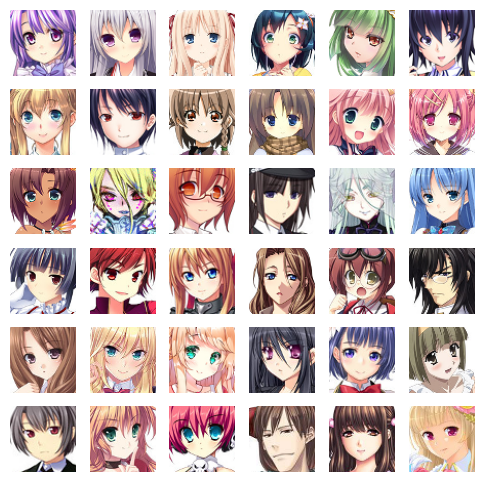

In [187]:
anime_faces = ImageFolder(
    anime_faces_path,
    transform=transforms.Compose(
        [
            transforms.ToImage(),
            transforms.ToDtype(torch.float32, scale=True),
            transforms.Resize(64),
            transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
        ]
    ),
)

plot_dataset(anime_faces, n_cols=6, n_rows=6, denormalize=True)

Number of samples: 34482
Sample shape: torch.Size([3, 64, 64])


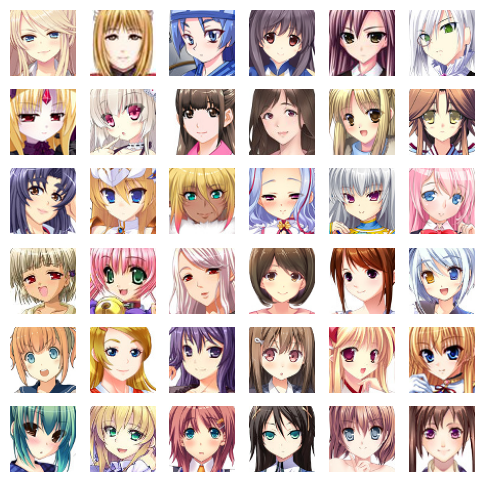

In [197]:
train_dataset, val_dataset = random_split(
    anime_faces, [0.8, 0.2], generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False, num_workers=0, pin_memory=True)

plot_dataset(train_dataset, n_cols=6, n_rows=6, denormalize=True)

In [198]:
epochs = 24
latent_dim = 128
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

generator = Generator(latent_dim)
discriminator = PatchDiscriminator()

g_optimizer = torch.optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
d_optimizer = torch.optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))
criterion = nn.BCELoss()

  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 1/24]
	G_Trn_Loss: 0.8563	D_Trn_Loss: 1.2579	D_Trn_Real: 0.5414	D_Trn_Fake: 0.5121	D_Trn_Acc: 71.66% 
	G_Val_Loss: 0.7254	D_Val_Loss: 1.3016	D_Val_Real: 0.5414	D_Val_Fake: 0.5121	D_Val_Acc: 65.00%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 2/24]
	G_Trn_Loss: 0.7543	D_Trn_Loss: 1.3298	D_Trn_Real: 0.5086	D_Trn_Fake: 0.5334	D_Trn_Acc: 65.06% 
	G_Val_Loss: 0.7666	D_Val_Loss: 1.3134	D_Val_Real: 0.5086	D_Val_Fake: 0.5334	D_Val_Acc: 67.71%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 3/24]
	G_Trn_Loss: 0.7421	D_Trn_Loss: 1.3428	D_Trn_Real: 0.5128	D_Trn_Fake: 0.5251	D_Trn_Acc: 61.85% 
	G_Val_Loss: 0.7522	D_Val_Loss: 1.3252	D_Val_Real: 0.5128	D_Val_Fake: 0.5251	D_Val_Acc: 62.62%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 4/24]
	G_Trn_Loss: 0.7274	D_Trn_Loss: 1.3586	D_Trn_Real: 0.4658	D_Trn_Fake: 0.5528	D_Trn_Acc: 58.64% 
	G_Val_Loss: 0.8691	D_Val_Loss: 1.4500	D_Val_Real: 0.4658	D_Val_Fake: 0.5528	D_Val_Acc: 53.84%


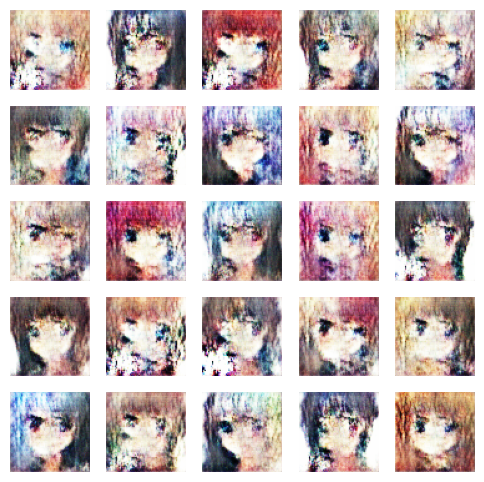

  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 5/24]
	G_Trn_Loss: 0.7263	D_Trn_Loss: 1.3628	D_Trn_Real: 0.5009	D_Trn_Fake: 0.5135	D_Trn_Acc: 57.60% 
	G_Val_Loss: 0.7250	D_Val_Loss: 1.3681	D_Val_Real: 0.5009	D_Val_Fake: 0.5135	D_Val_Acc: 56.20%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 6/24]
	G_Trn_Loss: 0.7253	D_Trn_Loss: 1.3645	D_Trn_Real: 0.5164	D_Trn_Fake: 0.5029	D_Trn_Acc: 57.27% 
	G_Val_Loss: 0.7016	D_Val_Loss: 1.3550	D_Val_Real: 0.5164	D_Val_Fake: 0.5029	D_Val_Acc: 58.93%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 7/24]
	G_Trn_Loss: 0.7283	D_Trn_Loss: 1.3620	D_Trn_Real: 0.5246	D_Trn_Fake: 0.4991	D_Trn_Acc: 57.68% 
	G_Val_Loss: 0.6965	D_Val_Loss: 1.3521	D_Val_Real: 0.5246	D_Val_Fake: 0.4991	D_Val_Acc: 59.52%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 8/24]
	G_Trn_Loss: 0.7313	D_Trn_Loss: 1.3579	D_Trn_Real: 0.5259	D_Trn_Fake: 0.5003	D_Trn_Acc: 58.36% 
	G_Val_Loss: 0.6975	D_Val_Loss: 1.3443	D_Val_Real: 0.5259	D_Val_Fake: 0.5003	D_Val_Acc: 59.30%


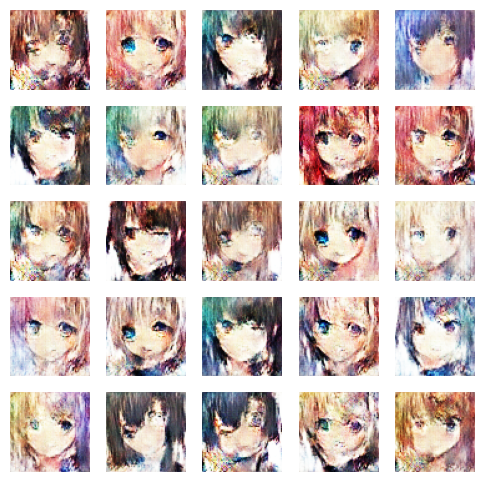

  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 9/24]
	G_Trn_Loss: 0.7353	D_Trn_Loss: 1.3622	D_Trn_Real: 0.5065	D_Trn_Fake: 0.5117	D_Trn_Acc: 58.93% 
	G_Val_Loss: 0.7198	D_Val_Loss: 1.3576	D_Val_Real: 0.5065	D_Val_Fake: 0.5117	D_Val_Acc: 59.16%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 10/24]
	G_Trn_Loss: 0.7387	D_Trn_Loss: 1.3481	D_Trn_Real: 0.5002	D_Trn_Fake: 0.5318	D_Trn_Acc: 60.43% 
	G_Val_Loss: 0.7636	D_Val_Loss: 1.3344	D_Val_Real: 0.5002	D_Val_Fake: 0.5318	D_Val_Acc: 63.33%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 11/24]
	G_Trn_Loss: 0.7506	D_Trn_Loss: 1.3382	D_Trn_Real: 0.5209	D_Trn_Fake: 0.5223	D_Trn_Acc: 61.52% 
	G_Val_Loss: 0.7449	D_Val_Loss: 1.3144	D_Val_Real: 0.5209	D_Val_Fake: 0.5223	D_Val_Acc: 65.15%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 12/24]
	G_Trn_Loss: 0.7513	D_Trn_Loss: 1.3468	D_Trn_Real: 0.5106	D_Trn_Fake: 0.5236	D_Trn_Acc: 61.41% 
	G_Val_Loss: 0.7468	D_Val_Loss: 1.3305	D_Val_Real: 0.5106	D_Val_Fake: 0.5236	D_Val_Acc: 63.75%


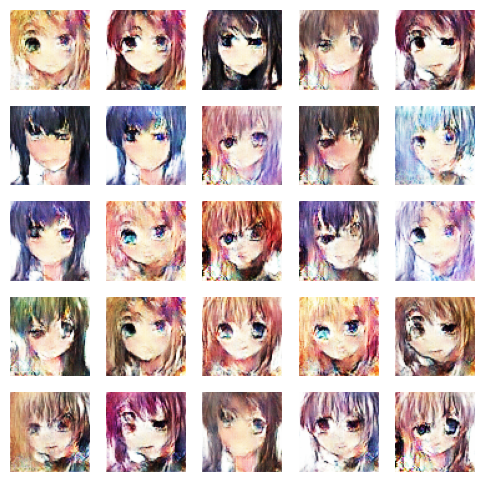

  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 13/24]
	G_Trn_Loss: 0.7573	D_Trn_Loss: 1.3291	D_Trn_Real: 0.5405	D_Trn_Fake: 0.5009	D_Trn_Acc: 62.70% 
	G_Val_Loss: 0.7031	D_Val_Loss: 1.3251	D_Val_Real: 0.5405	D_Val_Fake: 0.5009	D_Val_Acc: 61.69%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 14/24]
	G_Trn_Loss: 0.7693	D_Trn_Loss: 1.3201	D_Trn_Real: 0.5060	D_Trn_Fake: 0.5402	D_Trn_Acc: 63.72% 
	G_Val_Loss: 0.7882	D_Val_Loss: 1.3187	D_Val_Real: 0.5060	D_Val_Fake: 0.5402	D_Val_Acc: 62.67%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 15/24]
	G_Trn_Loss: 0.7332	D_Trn_Loss: 1.3800	D_Trn_Real: 0.5114	D_Trn_Fake: 0.5213	D_Trn_Acc: 56.33% 
	G_Val_Loss: 0.7407	D_Val_Loss: 1.3316	D_Val_Real: 0.5114	D_Val_Fake: 0.5213	D_Val_Acc: 63.90%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 16/24]
	G_Trn_Loss: 0.7552	D_Trn_Loss: 1.3275	D_Trn_Real: 0.5131	D_Trn_Fake: 0.5333	D_Trn_Acc: 63.05% 
	G_Val_Loss: 0.7683	D_Val_Loss: 1.3096	D_Val_Real: 0.5131	D_Val_Fake: 0.5333	D_Val_Acc: 66.06%


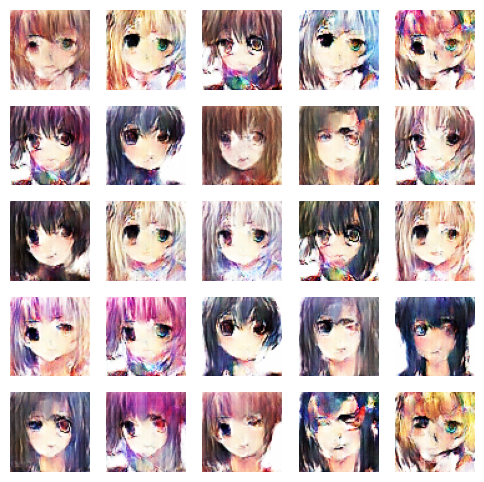

  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 17/24]
	G_Trn_Loss: 0.7722	D_Trn_Loss: 1.3126	D_Trn_Real: 0.5261	D_Trn_Fake: 0.5185	D_Trn_Acc: 64.44% 
	G_Val_Loss: 0.7379	D_Val_Loss: 1.3147	D_Val_Real: 0.5261	D_Val_Fake: 0.5185	D_Val_Acc: 63.95%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 18/24]
	G_Trn_Loss: 0.7548	D_Trn_Loss: 1.3530	D_Trn_Real: 0.5084	D_Trn_Fake: 0.5460	D_Trn_Acc: 60.73% 
	G_Val_Loss: 0.7963	D_Val_Loss: 1.2961	D_Val_Real: 0.5084	D_Val_Fake: 0.5460	D_Val_Acc: 67.61%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 19/24]
	G_Trn_Loss: 0.7734	D_Trn_Loss: 1.3115	D_Trn_Real: 0.5162	D_Trn_Fake: 0.5331	D_Trn_Acc: 64.65% 
	G_Val_Loss: 0.7687	D_Val_Loss: 1.3054	D_Val_Real: 0.5162	D_Val_Fake: 0.5331	D_Val_Acc: 66.55%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 20/24]
	G_Trn_Loss: 0.7882	D_Trn_Loss: 1.3105	D_Trn_Real: 0.5070	D_Trn_Fake: 0.4210	D_Trn_Acc: 64.95% 
	G_Val_Loss: 1.3218	D_Val_Loss: 3.1617	D_Val_Real: 0.5070	D_Val_Fake: 0.4210	D_Val_Acc: 45.46%


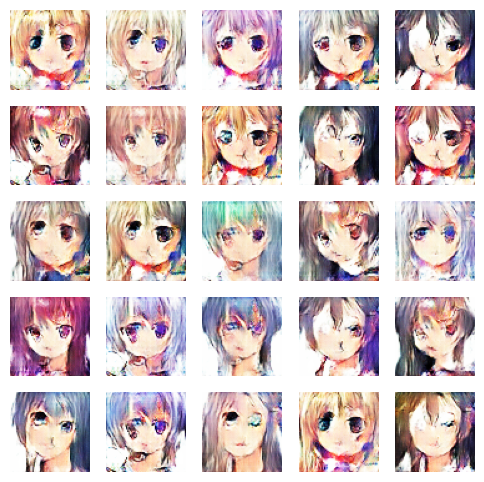

  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 21/24]
	G_Trn_Loss: 0.7782	D_Trn_Loss: 1.3145	D_Trn_Real: 0.5313	D_Trn_Fake: 0.5318	D_Trn_Acc: 65.11% 
	G_Val_Loss: 0.7680	D_Val_Loss: 1.2824	D_Val_Real: 0.5313	D_Val_Fake: 0.5318	D_Val_Acc: 67.89%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 22/24]
	G_Trn_Loss: 0.7883	D_Trn_Loss: 1.2967	D_Trn_Real: 0.5399	D_Trn_Fake: 0.5317	D_Trn_Acc: 65.53% 
	G_Val_Loss: 0.7744	D_Val_Loss: 1.2776	D_Val_Real: 0.5399	D_Val_Fake: 0.5317	D_Val_Acc: 66.84%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 23/24]
	G_Trn_Loss: 0.7812	D_Trn_Loss: 1.3248	D_Trn_Real: 0.5288	D_Trn_Fake: 0.5335	D_Trn_Acc: 63.61% 
	G_Val_Loss: 0.7714	D_Val_Loss: 1.2837	D_Val_Real: 0.5288	D_Val_Fake: 0.5335	D_Val_Acc: 67.62%


  0%|          | 0/270 [00:00<?, ?batch/s]

[Epoch 24/24]
	G_Trn_Loss: 0.7943	D_Trn_Loss: 1.2914	D_Trn_Real: 0.5394	D_Trn_Fake: 0.5327	D_Trn_Acc: 66.04% 
	G_Val_Loss: 0.7706	D_Val_Loss: 1.2668	D_Val_Real: 0.5394	D_Val_Fake: 0.5327	D_Val_Acc: 69.43%


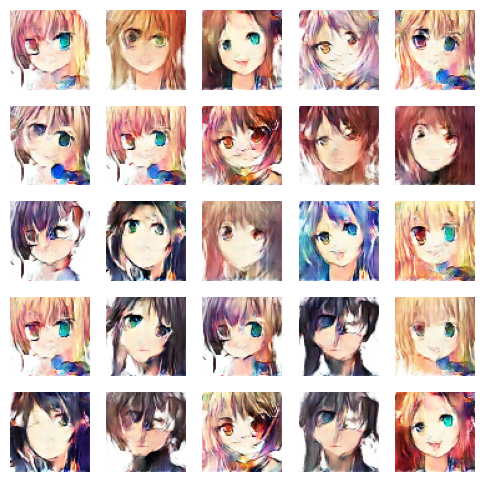

In [199]:
train_stats, val_stats = train(
    generator,
    discriminator,
    train_loader,
    val_loader,
    g_optimizer,
    d_optimizer,
    criterion,
    device,
    epochs=epochs,
    plot_frequency=4,
)

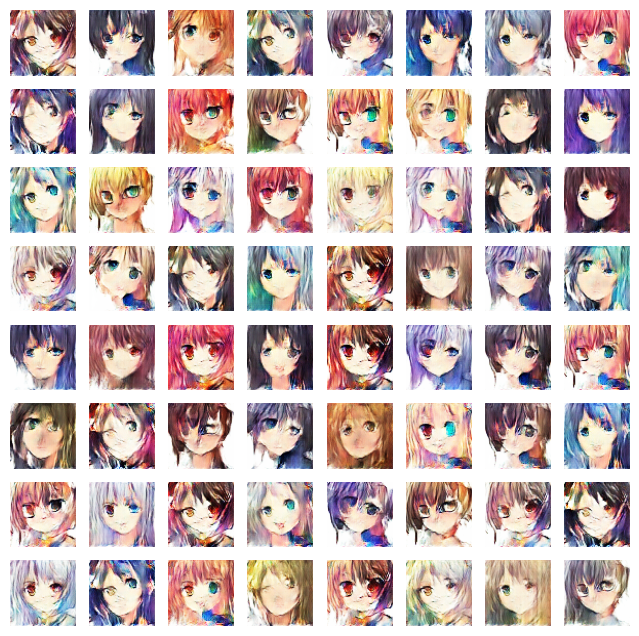

In [200]:
plot_generated_images(generator, device=device, num_images=64, denormalize=True, figsize=(8, 8))